In [ ]:
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr
!pip install -q opencv-python-headless pytesseract scikit-image matplotlib pandas

In [ ]:
from google.colab import files
import os
import cv2
import matplotlib.pyplot as plt

uploaded = files.upload()

os.makedirs("/content/ijazah", exist_ok=True)

for nama, isi in uploaded.items():
    path = os.path.join("/content/ijazah", nama)
    with open(path, "wb") as f:
        f.write(isi)

print("Jumlah gambar yang berhasil diunggah:", len(uploaded))
print("Nama file:", list(uploaded.keys()))

In [ ]:
import glob

gambar_files = sorted(glob.glob("/content/ijazah/*"))

for path in gambar_files:
    img = cv2.imread(path)

    if img is None:
        print("Gagal membaca:", path)
        continue

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 5))
    plt.imshow(img_rgb)
    plt.title(os.path.basename(path))
    plt.axis("off")
    plt.show()

    print("Ukuran gambar:", img.shape)

In [ ]:
import cv2
import matplotlib.pyplot as plt
import os
import glob

def enhancement_methods(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # 1. Grayscale
    grayscale = gray

    # 2. CLAHE
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )
    contrast = clahe.apply(gray)

    # 3. Sharpening
    denoised = cv2.GaussianBlur(gray, (3, 3), 0)
    sharpened = cv2.addWeighted(
        gray, 1.5, denoised, -0.5, 0
    )

    # 4. Adaptive Threshold
    threshold = cv2.adaptiveThreshold(
        contrast, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        31, 11
    )

    return {
        "Grayscale": grayscale,
        "CLAHE": contrast,
        "Sharpening": sharpened,
        "Adaptive Threshold": threshold
    }

# Ambil semua gambar dalam folder ijazah
gambar_files = sorted(
    glob.glob("/content/ijazah/*.jpg") +
    glob.glob("/content/ijazah/*.jpeg") +
    glob.glob("/content/ijazah/*.png")
)

print("Jumlah gambar:", len(gambar_files))

if len(gambar_files) == 0:
    print("Gambar tidak ditemukan. Periksa folder /content/ijazah.")
else:
    for path in gambar_files:
        img = cv2.imread(path)

        if img is None:
            print("Gagal membaca:", path)
            continue

        hasil = enhancement_methods(img)

        fig, axes = plt.subplots(2, 2, figsize=(14, 10))
        fig.suptitle(
            "Hasil Enhancement: " + os.path.basename(path),
            fontsize=14
        )

        for ax, (nama, citra) in zip(
            axes.flatten(), hasil.items()
        ):
            ax.imshow(citra, cmap="gray")
            ax.set_title(nama)
            ax.axis("off")

        plt.tight_layout()
        plt.show()

In [ ]:
import cv2
import pytesseract
import pandas as pd
import os

# Pastikan fungsi enhancement_methods terdefinisi, jika belum buat fungsi fallback
try:
    # Cek apakah fungsi sudah ada di namespace
    _ = enhancement_methods
except NameError:
    def enhancement_methods(img):
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        # 1. Grayscale
        grayscale = gray

        # 2. CLAHE
        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        )
        contrast = clahe.apply(gray)

        # 3. Sharpening
        denoised = cv2.GaussianBlur(gray, (3, 3), 0)
        sharpened = cv2.addWeighted(
            gray, 1.5, denoised, -0.5, 0
        )

        # 4. Adaptive Threshold
        threshold = cv2.adaptiveThreshold(
            contrast, 255,
            cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            cv2.THRESH_BINARY,
            31, 11
        )

        return {
            "Grayscale": grayscale,
            "CLAHE": contrast,
            "Sharpening": sharpened,
            "Adaptive Threshold": threshold
        }

hasil_ocr = []

for path in gambar_files:
    img = cv2.imread(path)

    if img is None:
        continue

    metode = enhancement_methods(img)

    for nama_metode, citra in metode.items():
        # Batasi ukuran gambar agar proses lebih cepat
        tinggi, lebar = citra.shape[:2]
        skala = min(1.0, 1400 / max(tinggi, lebar))

        if skala < 1.0:
            citra = cv2.resize(
                citra, None,
                fx=skala, fy=skala,
                interpolation=cv2.INTER_AREA
            )

        # Amankan proses OCR dengan try-except agar tidak menghentikan seluruh program saat timeout/error
        try:
            teks = pytesseract.image_to_string(
                citra,
                config="--oem 3 --psm 6",
                timeout=40
            )
            teks_clean = teks.strip()
        except RuntimeError as e:
            print(f"Gagal/Timeout pada {os.path.basename(path)} ({nama_metode}): {e}")
            teks_clean = "[GAGAL OCR / TIMEOUT]"

        hasil_ocr.append({
            "Nama File": os.path.basename(path),
            "Metode": nama_metode,
            "Teks OCR": teks_clean
        })

    print("Selesai:", os.path.basename(path))

df_ocr = pd.DataFrame(hasil_ocr)

display(df_ocr[["Nama File", "Metode", "Teks OCR"]])

In [ ]:
df_ocr.to_csv(
    "/content/hasil_ocr_ijazah.csv",
    index=False,
    encoding="utf-8-sig"
)

from google.colab import files
files.download("/content/hasil_ocr_ijazah.csv")

In [ ]:
import cv2
import os
import re
import pandas as pd
import pytesseract

# Koordinat area potongan presisi
area_nomor = (350, 2180, 1150, 2390)
area_ttd_rektor = (650, 1650, 1450, 2100)
area_ttd_dekan = (2200, 1600, 2900, 2100)

# Fungsi ekstraksi nomor ijazah yang tangguh dengan fallback angka panjang
def ekstrak_nomor_ijazah_robust(teks):
    teks_clean = teks.replace("\n", " ").strip()

    # Pola 1: Mencari dengan kata kunci No/Nomor
    pola = [
        r'(?i)N[CO]\.?\s*[:\-]?\s*([A-Z0-9./-]+)',
        r'(?i)nomor\s+ijazah\s*[:\-]?\s*([A-Z0-9./-]+)',
        r'(?i)ijazah\s*[:\-]?\s*([A-Z0-9./-]+)'
    ]

    for p in pola:
        hasil = re.search(p, teks_clean)
        if hasil:
            clean_res = hasil.group(1).strip().strip(".:-")
            if len(clean_res) >= 10:
                return clean_res

    # Fallback: Cari deretan angka panjang (10-15 digit) langsung dari teks
    kandidat_angka = re.findall(r'\d{10,15}', teks_clean)
    if kandidat_angka:
        return max(kandidat_angka, key=len)

    return "Tidak terbaca"

# Fungsi pendeteksi keberadaan tanda tangan berdasarkan rasio kepadatan tinta
def verifikasi_tanda_tangan(roi):
    gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
    thresh = cv2.adaptiveThreshold(
        gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 15, 5
    )
    total_pixels = thresh.size
    ink_pixels = cv2.countNonZero(thresh)
    ratio = (ink_pixels / total_pixels) * 100
    status = "Ada" if ratio > 1.5 else "Tidak Ada"
    return status, ratio

hasil_evaluasi_lengkap = []

if 'gambar_tegak' in globals() and len(gambar_tegak) > 0:
    for nama_file, img in gambar_tegak.items():
        h, w = img.shape[:2]

        # Pemotongan ROI
        roi_num = img[max(0, area_nomor[1]):min(h, area_nomor[3]), max(0, area_nomor[0]):min(w, area_nomor[2])]
        roi_rektor = img[max(0, area_ttd_rektor[1]):min(h, area_ttd_rektor[3]), max(0, area_ttd_rektor[0]):min(w, area_ttd_rektor[2])]
        roi_dekan = img[max(0, area_ttd_dekan[1]):min(h, area_ttd_dekan[3]), max(0, area_ttd_dekan[0]):min(w, area_ttd_dekan[2])]

        # Peningkatan kualitas citra nomor ijazah dengan CLAHE sebelum OCR
        gray_num = cv2.cvtColor(roi_num, cv2.COLOR_BGR2GRAY)
        clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
        enhanced_num = clahe.apply(gray_num)

        # Ekstraksi Teks OCR
        teks_ocr = pytesseract.image_to_string(enhanced_num, config="--oem 3 --psm 6")
        nomor_final = ekstrak_nomor_ijazah_robust(teks_ocr)

        # Verifikasi Tanda Tangan
        status_rektor, rasio_rektor = verifikasi_tanda_tangan(roi_rektor)
        status_dekan, rasio_dekan = verifikasi_tanda_tangan(roi_dekan)

        hasil_evaluasi_lengkap.append({
            "Nama File": nama_file,
            "Nomor Ijazah": nomor_final,
            "Ttd Rektor": status_rektor,
            "Kepadatan Tinta Rektor (%)": round(rasio_rektor, 2),
            "Ttd Dekan": status_dekan,
            "Kepadatan Tinta Dekan (%)": round(rasio_dekan, 2)
        })

    # Menampilkan hasil kompilasi akhir
    df_final_verifikasi = pd.DataFrame(hasil_evaluasi_lengkap)
    display(df_final_verifikasi)

    # Ekspor ke file CSV
    df_final_verifikasi.to_csv("/content/hasil_verifikasi_seluruh_ijazah.csv", index=False, encoding="utf-8-sig")
    print("\nHasil otomatisasi verifikasi 9 ijazah sukses diekspor ke /content/hasil_verifikasi_seluruh_ijazah.csv")
else:
    print("Error: Data gambar_tegak tidak ditemukan.")

In [ ]:

from jiwer import cer

# Ganti dengan nomor yang benar dari gambar masing-masing.
nomor_acuan = {
    # "nama_file.jpg": "NOMOR_IJAZAH_SEBENARNYA",
}

evaluasi = []

for _, row in df_ocr.iterrows():
    nama_file = row["Nama File"]
    metode = row["Metode"]

    if nama_file not in nomor_acuan:
        continue

    acuan = nomor_acuan[nama_file]
    prediksi = row["Teks OCR"]

    nilai_cer = cer(acuan, prediksi)

    evaluasi.append({
        "Nama File": nama_file,
        "Metode": metode,
        "CER": nilai_cer
    })

df_cer = pd.DataFrame(evaluasi)

if not df_cer.empty:
    display(
        df_cer.sort_values("CER")
    )

    print("Rata-rata CER setiap metode:")
    display(
        df_cer.groupby("Metode")["CER"]
        .mean()
        .sort_values()
        .reset_index()
    )
else:
    print(
        "Masukkan nomor acuan sebenarnya terlebih dahulu "
        "ke dictionary nomor_acuan."
    )

In [ ]:
import re

def ekstrak_nomor_ijazah(teks):
    teks = teks.replace("\n", " ")

    pola = [
        r'(?i)N[CO]\.?\s*[:\-]?\s*([A-Z]{0,3}[-.]?\s*\d{2,}(?:[-.]\d+)*)',
        r'(?i)nomor\s+ijazah\s*[:\-]?\s*([A-Z0-9./-]+)'
    ]

    for p in pola:
        hasil = re.search(p, teks)
        if hasil:
            return hasil.group(1).strip()

    return "Tidak terbaca"

In [ ]:
import cv2
import os
import re
import pandas as pd
import pytesseract
import matplotlib.pyplot as plt

# Fungsi enhancement sudah dibuat pada kode sebelumnya.
# Fungsi ekstrak_nomor_ijazah dan deteksi_tanda_tangan
# juga harus sudah tersedia.

hasil_verifikasi = []

for path in gambar_files:
    img = cv2.imread(path)

    if img is None:
        print("Gagal membaca:", path)
        continue

    tinggi, lebar = img.shape[:2]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Tampilkan gambar untuk membantu menentukan area
    print("\nMemproses:", os.path.basename(path))
    print("Ukuran:", lebar, "x", tinggi)

    plt.figure(figsize=(9, 5))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(os.path.basename(path))
    plt.axis("on")
    plt.show()

    print("Catat koordinat area nomor dan tanda tangan dari gambar di atas.")


In [ ]:
# GANTI koordinat berdasarkan gambar ijazahmu.
# Format: (x1, y1, x2, y2)

area_ijazah = {
    "ijazah_001.jpg": {
        "nomor": (100, 100, 600, 250),
        "ttd": (300, 400, 750, 650)
    },
    # Tambahkan file lainnya di sini.
    # "ijazah_002.jpg": {
    #     "nomor": (x1, y1, x2, y2),
    #     "ttd": (x1, y1, x2, y2)
    # }
}

In [ ]:
hasil_verifikasi = []

for path in gambar_files:
    nama_file = os.path.basename(path)

    if nama_file not in area_ijazah:
        print("Area belum ditentukan:", nama_file)
        continue

    img = cv2.imread(path)
    h, w = img.shape[:2]

    # Potong area nomor
    x1, y1, x2, y2 = area_ijazah[nama_file]["nomor"]
    roi_nomor = img[
        max(0, y1):min(h, y2),
        max(0, x1):min(w, x2)
    ]

    # Potong area tanda tangan
    a1, b1, a2, b2 = area_ijazah[nama_file]["ttd"]
    roi_ttd = img[
        max(0, b1):min(h, b2),
        max(0, a1):min(w, a2)
    ]

    if roi_nomor.size == 0 or roi_ttd.size == 0:
        print("ROI kosong, periksa koordinat:", nama_file)
        continue

    # Enhancement area nomor
    gray_nomor = cv2.cvtColor(
        roi_nomor, cv2.COLOR_BGR2GRAY
    )
    clahe = cv2.createCLAHE(
        clipLimit=2.0, tileGridSize=(8, 8)
    )
    enhanced = clahe.apply(gray_nomor)

    # OCR
    teks = pytesseract.image_to_string(
        enhanced, config="--oem 3 --psm 6"
    )
    nomor = ekstrak_nomor_ijazah(teks)

    # Deteksi indikasi tanda tangan
    status, rasio, mask = deteksi_tanda_tangan(roi_ttd)

    hasil_verifikasi.append({
        "Nama File": nama_file,
        "Nomor Ijazah": nomor,
        "Tanda Tangan": status,
        "Rasio Tinta": round(rasio, 4)
    })

df_verifikasi = pd.DataFrame(hasil_verifikasi)
display(df_verifikasi)

df_verifikasi.to_csv(
    "/content/hasil_verifikasi_ijazah.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Hasil tersimpan di hasil_verifikasi_ijazah.csv")

In [ ]:
import cv2
import matplotlib.pyplot as plt
import os

# Koordinat gambar tegak: x1, y1, x2, y2
area_nomor = (350, 2180, 1150, 2390)
area_ttd_rektor = (650, 1650, 1450, 2100)
area_ttd_dekan = (2200, 1600, 2900, 2100)

area = [
    ("Nomor Ijazah", area_nomor),
    ("Tanda Tangan Rektor", area_ttd_rektor),
    ("Tanda Tangan Dekan", area_ttd_dekan)
]

# Memastikan variabel gambar_tegak tersedia
if 'gambar_tegak' in globals() and len(gambar_tegak) > 0:
    # Proses semua gambar ijazah yang sudah diputar tegak di memori
    for nama_file, img in gambar_tegak.items():
        print("Nama ijazah:", nama_file)

        fig, ax = plt.subplots(1, 3, figsize=(15, 5))
        h, w = img.shape[:2]

        for a, (judul, (x1, y1, x2, y2)) in zip(ax, area):
            # Mengamankan koordinat agar tidak melewati batas dimensi gambar
            crop = img[max(0, y1):min(h, y2), max(0, x1):min(w, x2)]

            if crop.size == 0:
                a.set_title(judul + " - Area kosong")
                a.axis("off")
                continue

            a.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
            a.set_title(judul)
            a.axis("off")

        plt.suptitle(nama_file)
        plt.tight_layout()
        plt.show()
else:
    print("Error: Dictionary 'gambar_tegak' tidak ditemukan. Harap jalankan kembali sel rc7igoWoH_Sn terlebih dahulu.")

In [ ]:
import cv2
import matplotlib.pyplot as plt
import os

def enhancement_methods(roi):
    gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)

    # 1. Grayscale
    grayscale = gray

    # 2. CLAHE: meningkatkan kontras lokal
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )
    contrast = clahe.apply(gray)

    # 3. Sharpening: mempertajam detail
    blur = cv2.GaussianBlur(gray, (0, 0), 3)
    sharpen = cv2.addWeighted(gray, 1.5, blur, -0.5, 0)

    # 4. Adaptive Threshold: membuat citra hitam-putih
    adaptive = cv2.adaptiveThreshold(
        contrast, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        31, 11
    )

    return {
        "Grayscale": grayscale,
        "CLAHE": contrast,
        "Sharpening": sharpen,
        "Adaptive Threshold": adaptive
    }

# Memastikan variabel gambar_tegak dan area_nomor tersedia
if 'gambar_tegak' in globals() and 'area_nomor' in globals():
    # Tampilkan perbandingan enhancement pada area nomor
    for nama_file, img in gambar_tegak.items():
        h, w = img.shape[:2]
        x1, y1, x2, y2 = area_nomor

        # Mengamankan koordinat pemotongan
        roi_nomor = img[max(0, y1):min(h, y2), max(0, x1):min(w, x2)]

        if roi_nomor.size == 0:
            continue

        hasil_enhancement = enhancement_methods(roi_nomor)

        fig, ax = plt.subplots(1, 4, figsize=(16, 4))

        for a, (nama, citra) in zip(
            ax, hasil_enhancement.items()
        ):
            a.imshow(citra, cmap="gray")
            a.set_title(nama)
            a.axis("off")

        plt.suptitle(nama_file)
        plt.tight_layout()
        plt.show()
else:
    print("Error: Pastikan 'gambar_tegak' dan 'area_nomor' telah didefinisikan terlebih dahulu.")

In [63]:
import os
import glob
import cv2

folder_ijazah = "/content/ijazah"

gambar_tegak_files = sorted(
    glob.glob(os.path.join(folder_ijazah, "*.jpg")) +
    glob.glob(os.path.join(folder_ijazah, "*.jpeg")) +
    glob.glob(os.path.join(folder_ijazah, "*.png"))
)

print("Jumlah gambar ditemukan:", len(gambar_tegak_files))

for path in gambar_tegak_files:
    print(os.path.basename(path))

Jumlah gambar ditemukan: 9
01_HighQuality_Enhanced.jpg
02_LowContrast.jpg
03_Blurred.jpg
04_HighNoise.jpg
05_LowResolution_Upsampled.jpg
06_Faded_Underexposed.jpg
07_ColorShift_WarmTint.jpg
08_JPEGCompression_Artifacts.jpg
09_CombinedDegradation.jpg


In [62]:
import cv2
import re
import os
import pandas as pd
import pytesseract
from IPython.display import display

# ==========================================
# 1. PENGATURAN PROYEK
# ==========================================

nomor_acuan = "571012022000056"

# Koordinat: (x1, y1, x2, y2)
area_nomor = (350, 2180, 1150, 2390)
area_ttd_rektor = (650, 1650, 1450, 2100)
area_ttd_dekan = (2200, 1600, 2900, 2100)

# ==========================================
# 2. METODE PENINGKATAN CITRA
# ==========================================

def enhancement_methods(roi):
    gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )
    contrast = clahe.apply(gray)

    blur = cv2.GaussianBlur(gray, (0, 0), 2)
    sharpen = cv2.addWeighted(gray, 1.8, blur, -0.8, 0)

    adaptive = cv2.adaptiveThreshold(
        contrast, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY, 31, 11
    )

    return {
        "Grayscale": gray,
        "CLAHE": contrast,
        "Sharpening": sharpen,
        "Adaptive Threshold": adaptive
    }

# ==========================================
# 3. DETEKSI INDIKASI TANDA TANGAN
# ==========================================

def deteksi_tanda_tangan(roi):
    if roi.size == 0:
        return "Area kosong", 0.0

    gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)

    thresh = cv2.adaptiveThreshold(
        gray, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV, 15, 5
    )

    rasio = cv2.countNonZero(thresh) / thresh.size * 100
    status = "Ada indikasi tinta" if rasio > 1.5 else "Tidak terdeteksi"

    return status, round(rasio, 2)

# ==========================================
# 4. FUNGSI HITUNG CER
# ==========================================

def hitung_edit_distance(a, b):
    dp = list(range(len(b) + 1))

    for i, ca in enumerate(a, start=1):
        baru = [i]

        for j, cb in enumerate(b, start=1):
            biaya = 0 if ca == cb else 1
            baru.append(min(
                baru[-1] + 1,
                dp[j] + 1,
                dp[j - 1] + biaya
            ))

        dp = baru

    return dp[-1]

def hitung_cer(acuan, prediksi):
    if not prediksi:
        return 1.0

    return hitung_edit_distance(acuan, prediksi) / len(acuan)

# ==========================================
# 5. PROSES SEMUA IJAZAH
# ==========================================

hasil = []
jumlah = len(gambar_tegak)

print("Jumlah ijazah:", jumlah)

for nomor_gambar, (nama_file, img) in enumerate(
    gambar_tegak.items(), start=1
):
    h, w = img.shape[:2]

    def potong(area):
        x1, y1, x2, y2 = area
        return img[
            max(0, y1):min(h, y2),
            max(0, x1):min(w, x2)
        ]

    roi_nomor = potong(area_nomor)
    roi_rektor = potong(area_ttd_rektor)
    roi_dekan = potong(area_ttd_dekan)

    if roi_nomor.size == 0:
        print("Crop nomor kosong:", nama_file)
        continue

    status_rektor, tinta_rektor = deteksi_tanda_tangan(roi_rektor)
    status_dekan, tinta_dekan = deteksi_tanda_tangan(roi_dekan)

    metode = enhancement_methods(roi_nomor)

    for nama_metode, citra in metode.items():
        # Perbesar crop untuk membantu pembacaan angka
        citra = cv2.resize(
            citra, None, fx=2, fy=2,
            interpolation=cv2.INTER_CUBIC
        )

        try:
            teks = pytesseract.image_to_string(
                citra,
                config=(
                    "--oem 3 --psm 7 "
                    "-c tessedit_char_whitelist=0123456789"
                ),
                timeout=10
            )

            nomor_ocr = re.sub(r"\D", "", teks)

        except RuntimeError:
            nomor_ocr = ""

        cer = hitung_cer(nomor_acuan, nomor_ocr)

        hasil.append({
            "Nama File": nama_file,
            "Metode": nama_metode,
            "Nomor Acuan": nomor_acuan,
            "Nomor Hasil OCR": nomor_ocr or "Tidak terbaca",
            "OCR Benar": nomor_ocr == nomor_acuan,
            "CER (%)": round(cer * 100, 2),
            "Tanda Tangan Rektor": status_rektor,
            "Tinta Rektor (%)": tinta_rektor,
            "Tanda Tangan Dekan": status_dekan,
            "Tinta Dekan (%)": tinta_dekan
        })

    print(f"[{nomor_gambar}/{jumlah}] Selesai: {nama_file}")

# ==========================================
# 6. TABEL DAN EKSPOR HASIL
# ==========================================

df_hasil = pd.DataFrame(hasil)

if not df_hasil.empty:
    display(df_hasil)

    df_hasil.to_csv(
        "/content/hasil_evaluasi_9_ijazah.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print("\nRata-rata CER setiap metode:")
    ringkasan = (
        df_hasil.groupby("Metode")
        .agg(
            Rata_rata_CER=("CER (%)", "mean"),
            Jumlah_OCR_Benar=("OCR Benar", "sum")
        )
        .sort_values("Rata_rata_CER")
        .round(2)
    )
    display(ringkasan)

    print("File tersimpan: /content/hasil_evaluasi_9_ijazah.csv")

else:
    print("Belum ada hasil. Periksa gambar dan koordinat crop.")

Jumlah ijazah: 9
[1/9] Selesai: 01_HighQuality_Enhanced.jpg
[2/9] Selesai: 02_LowContrast.jpg
[3/9] Selesai: 03_Blurred.jpg
[4/9] Selesai: 04_HighNoise.jpg
[5/9] Selesai: 05_LowResolution_Upsampled.jpg
[6/9] Selesai: 06_Faded_Underexposed.jpg
[7/9] Selesai: 07_ColorShift_WarmTint.jpg
[8/9] Selesai: 08_JPEGCompression_Artifacts.jpg
[9/9] Selesai: 09_CombinedDegradation.jpg


,Nama File,Metode,Nomor Acuan,Nomor Hasil OCR,OCR Benar,CER (%),Tanda Tangan Rektor,Tinta Rektor (%),Tanda Tangan Dekan,Tinta Dekan (%)
0,01_HighQuality_Enhanced.jpg,Grayscale,571012022000056,571012022000056,True,0.00,Ada indikasi tinta,11.91,Ada indikasi tinta,13.36
1,01_HighQuality_Enhanced.jpg,CLAHE,571012022000056,571012022000056,True,0.00,Ada indikasi tinta,11.91,Ada indikasi tinta,13.36
2,01_HighQuality_Enhanced.jpg,Sharpening,571012022000056,571012022000056,True,0.00,Ada indikasi tinta,11.91,Ada indikasi tinta,13.36
3,01_HighQuality_Enhanced.jpg,Adaptive Threshold,571012022000056,Tidak terbaca,False,100.00,Ada indikasi tinta,11.91,Ada indikasi tinta,13.36
4,02_LowContrast.jpg,Grayscale,571012022000056,571012022000056,True,0.00,Ada indikasi tinta,5.62,Ada indikasi tinta,9.47
5,02_LowContrast.jpg,CLAHE,571012022000056,571012022000056,True,0.00,Ada indikasi tinta,5.62,Ada indikasi tinta,9.47
6,02_LowContrast.jpg,Sharpening,571012022000056,571012022000056,True,0.00,Ada indikasi tinta,5.62,Ada indikasi tinta,9.47
7,02_LowContrast.jpg,Adaptive Threshold,571012022000056,Tidak terbaca,False,100.00,Ada indikasi tinta,5.62,Ada indikasi tinta,9.47
8,03_Blurred.jpg,Grayscale,571012022000056,571012022000056,True,0.00,Ada indikasi tinta,4.54,Ada indikasi tinta,10.40
9,03_Blurred.jpg,CLAHE,571012022000056,571012022000056,True,0.00,Ada indikasi tinta,4.54,Ada indikasi tinta,10.40



Rata-rata CER setiap metode:


,Rata_rata_CER,Jumlah_OCR_Benar
Metode,,
Sharpening,0.00,9
Grayscale,0.00,9
CLAHE,11.11,8
Adaptive Threshold,87.41,1


File tersimpan: /content/hasil_evaluasi_9_ijazah.csv


In [60]:
# Ringkasan hasil evaluasi seluruh ijazah

ringkasan = (
    df_hasil.groupby("Metode")
    .agg(
        Total_Pengujian=("Nama File", "count"),
        OCR_Benar=("OCR Benar", "sum"),
        Rata_rata_CER=("CER (%)", "mean"),
        Indikasi_TTD_Rektor=(
            "Tanda Tangan Rektor",
            lambda x: (x == "Ada indikasi tinta").sum()
        ),
        Indikasi_TTD_Dekan=(
            "Tanda Tangan Dekan",
            lambda x: (x == "Ada indikasi tinta").sum()
        )
    )
    .reset_index()
    .round(2)
)

display(ringkasan)

ringkasan.to_csv(
    "/content/ringkasan_evaluasi_ijazah.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Ringkasan tersimpan di /content/ringkasan_evaluasi_ijazah.csv")

,Metode,Total_Pengujian,OCR_Benar,Rata_rata_CER,Indikasi_TTD_Rektor,Indikasi_TTD_Dekan
0,Adaptive Threshold,9,1,87.41,9,9
1,CLAHE,9,8,11.11,9,9
2,Grayscale,9,9,0.00,9,9
3,Sharpening,9,9,0.00,9,9


Ringkasan tersimpan di /content/ringkasan_evaluasi_ijazah.csv


In [ ]:
from google.colab import files

files.download("/content/ringkasan_evaluasi_ijazah.csv")

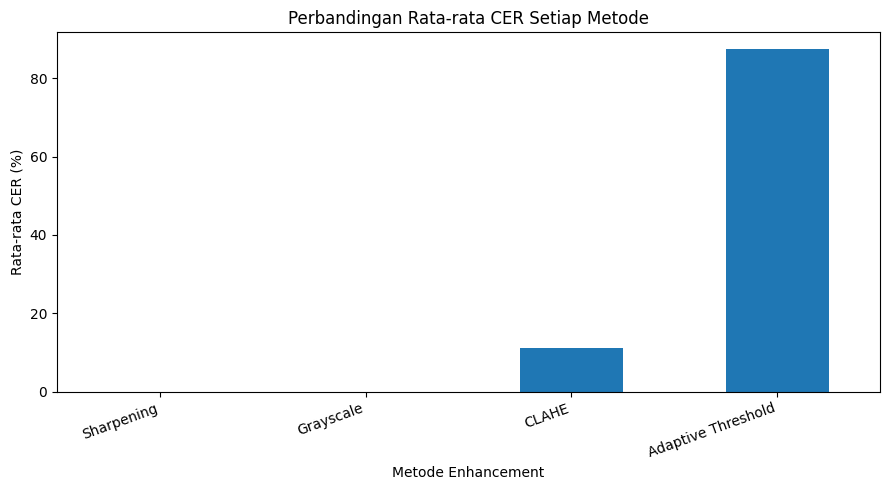

Rata-rata CER setiap metode:


,Metode,CER (%)
0,Sharpening,0.000000
1,Grayscale,0.000000
2,CLAHE,11.111111
3,Adaptive Threshold,87.407778


In [58]:
import matplotlib.pyplot as plt

# Hitung rata-rata CER setiap metode
rata_cer = (
    df_hasil.groupby("Metode")["CER (%)"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(9, 5))
rata_cer.plot(kind="bar")
plt.title("Perbandingan Rata-rata CER Setiap Metode")
plt.xlabel("Metode Enhancement")
plt.ylabel("Rata-rata CER (%)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

print("Rata-rata CER setiap metode:")
display(rata_cer.reset_index())

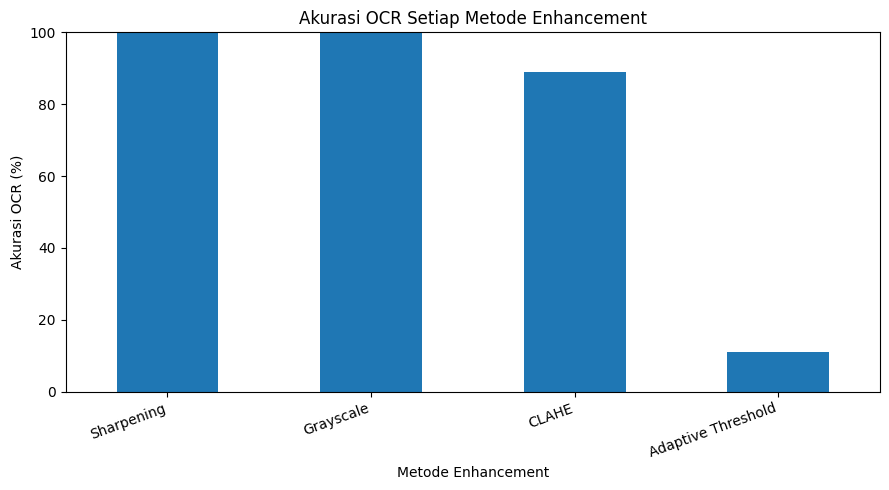

Persentase akurasi OCR:


,Metode,Akurasi (%)
0,Sharpening,100.00
1,Grayscale,100.00
2,CLAHE,88.89
3,Adaptive Threshold,11.11


In [57]:
import matplotlib.pyplot as plt
import pandas as pd

akurasi = (
    df_hasil.groupby("Metode")["OCR Benar"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
akurasi.plot(kind="bar")
plt.title("Akurasi OCR Setiap Metode Enhancement")
plt.xlabel("Metode Enhancement")
plt.ylabel("Akurasi OCR (%)")
plt.ylim(0, 100)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

print("Persentase akurasi OCR:")
display(akurasi.reset_index(name="Akurasi (%)").round(2))

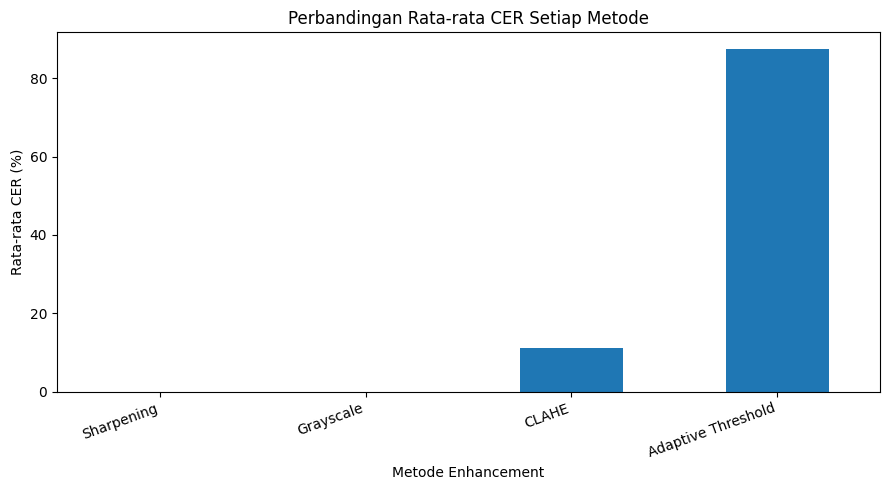

Ringkasan dan grafik berhasil dibuat.


,Metode,Total_Pengujian,OCR_Benar,Rata_rata_CER,Akurasi OCR (%)
0,Adaptive Threshold,9,1,87.41,11.11
1,CLAHE,9,8,11.11,88.89
2,Grayscale,9,9,0.00,100.00
3,Sharpening,9,9,0.00,100.00


In [59]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# Pastikan tabel hasil sebelumnya masih tersedia
if "df_hasil" not in globals():
    df_hasil = pd.read_csv("/content/hasil_evaluasi_9_ijazah.csv")

# Hitung ringkasan akurasi OCR
ringkasan = (
    df_hasil.groupby("Metode")
    .agg(
        Total_Pengujian=("OCR Benar", "count"),
        OCR_Benar=("OCR Benar", "sum"),
        Rata_rata_CER=("CER (%)", "mean")
    )
    .reset_index()
)

ringkasan["Akurasi OCR (%)"] = (
    ringkasan["OCR_Benar"] /
    ringkasan["Total_Pengujian"] * 100
).round(2)

ringkasan["Rata_rata_CER"] = (
    ringkasan["Rata_rata_CER"].round(2)
)

ringkasan.to_csv(
    "/content/ringkasan_akurasi_OCR.csv",
    index=False,
    encoding="utf-8-sig"
)

# Buat grafik perbandingan CER
rata_cer = (
    df_hasil.groupby("Metode")["CER (%)"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(9, 5))
rata_cer.plot(kind="bar")
plt.title("Perbandingan Rata-rata CER Setiap Metode")
plt.xlabel("Metode Enhancement")
plt.ylabel("Rata-rata CER (%)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig(
    "/content/grafik_perbandingan_CER.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Ringkasan dan grafik berhasil dibuat.")
display(ringkasan)

In [ ]:
import os
from google.colab import files

daftar_file = [
    "/content/hasil_evaluasi_9_ijazah.csv",
    "/content/ringkasan_akurasi_OCR.csv",
    "/content/grafik_perbandingan_CER.png"
]

for file in daftar_file:
    if os.path.exists(file):
        print("File tersedia:", os.path.basename(file))
    else:
        print("File belum ada:", os.path.basename(file))